# One IQR rule, two dead features

**Revisiting a loan-approval assignment.** The original pipeline scored *below the majority-class baseline*. The models were not the problem: the outlier step had turned the most informative feature into a constant.

Dataset: [Kaggle Loan Prediction Problem Dataset](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset), `train_u6lujuX_CVtuZ9i.csv` (614 applications). Download it and save it as `data/train.csv`.

In [1]:
import sys
sys.path.append("src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

from preprocessing import LoanPreprocessor, NUMERIC, CONTINUOUS

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

## 1. The data

In [2]:
df = pd.read_csv("data/train.csv")
y = (df["Loan_Status"] == "Y").astype(int)
X = df.drop(columns=["Loan_ID", "Loan_Status"])

print(df.shape)
print(f"approved: {y.mean():.1%}")
df.isna().sum()[lambda s: s > 0]

(614, 13)
approved: 68.7%


Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

In [3]:
print(df["Credit_History"].value_counts(dropna=False))
df.groupby("Credit_History")["Loan_Status"].apply(lambda s: (s == "Y").mean()).rename("approval rate")

Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64


Credit_History
0.0    0.078652
1.0    0.795789
Name: approval rate, dtype: float64

`Credit_History` is close to a rule: applicants who meet the credit guidelines are approved about 80% of the time, the rest under 10%. Any reasonable model should lean on it.

## 2. What the IQR rule does to a binary column

The original pipeline clipped **every numeric column** to `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. About 84% of `Credit_History` values are 1, so Q1 = Q3 = 1, IQR = 0, and every 0 is clipped up to 1. `Loan_Amount_Term` (85% are 360 months) collapses the same way.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

clip_all = LoanPreprocessor(clip_cols=NUMERIC).fit(X_tr)
clip_cont = LoanPreprocessor(clip_cols=CONTINUOUS).fit(X_tr)

for col in ["Credit_History", "Loan_Amount_Term"]:
    print(f"{col}: IQR bounds learned on train = {clip_all.bounds_[col]}")

before = clip_cont.transform(X_tr)
after = clip_all.transform(X_tr)
summary = pd.DataFrame({
    "distinct values (continuous-only clipping)": before[["Credit_History", "Loan_Amount_Term"]].nunique(),
    "distinct values (clip every numeric column)": after[["Credit_History", "Loan_Amount_Term"]].nunique(),
})
summary

Credit_History: IQR bounds learned on train = (1.0, 1.0)
Loan_Amount_Term: IQR bounds learned on train = (360.0, 360.0)


,distinct values (continuous-only clipping),distinct values (clip every numeric column)
Credit_History,6,1
Loan_Amount_Term,15,1


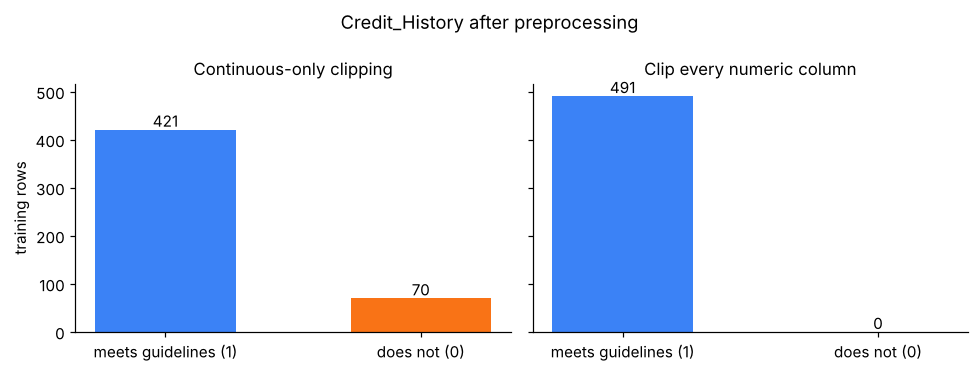

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (title, frame) in zip(axes, [("Continuous-only clipping", before), ("Clip every numeric column", after)]):
    vals = (frame["Credit_History"] >= 0.5).map({True: "meets guidelines (1)", False: "does not (0)"})
    counts = vals.value_counts().reindex(["meets guidelines (1)", "does not (0)"], fill_value=0)
    ax.bar(counts.index, counts.values, color=["#3b82f6", "#f97316"], width=0.55)
    ax.set_title(title, fontsize=11)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 6, str(v), ha="center", fontsize=10)
axes[0].set_ylabel("training rows")
fig.suptitle("Credit_History after preprocessing", fontsize=12)
fig.tight_layout()
fig.savefig("assets/credit_history_collapse.png", bbox_inches="tight")
plt.show()

## 3. Same models, same split, one change

Both pipelines are identical except for which columns are clipped. The preprocessor sits inside the pipeline, so imputation and IQR bounds are re-learned on each CV training fold (no test data leaks into them). Hyperparameters are tuned with 5-fold CV on the training split; the test split is used once.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Decision tree": (DecisionTreeClassifier(random_state=SEED),
                      {"clf__max_depth": [3, 5, 7, None], "clf__min_samples_leaf": [1, 3, 5]}),
    "Random forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5, None], "clf__min_samples_leaf": [1, 3]}),
    "SVM (RBF)": (Pipeline([("scale", StandardScaler()), ("svc", SVC(random_state=SEED))]),
                  {"clf__svc__C": [0.1, 1, 10], "clf__svc__gamma": ["scale", "auto"]}),
}
settings = {"Clip every numeric column (original)": NUMERIC, "Clip continuous columns only (fixed)": CONTINUOUS}

rows, fitted = [], {}
for setting, cols in settings.items():
    for name, (est, grid) in models.items():
        pipe = Pipeline([("prep", LoanPreprocessor(clip_cols=cols)), ("clf", est)])
        search = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_tr, y_tr)
        pred = search.predict(X_te)
        fitted[(setting, name)] = search.best_estimator_
        rows.append({"setting": setting, "model": name,
                     "CV accuracy": search.best_score_,
                     "test accuracy": accuracy_score(y_te, pred),
                     "test macro-F1": f1_score(y_te, pred, average="macro")})

results = pd.DataFrame(rows)
baseline = max(y_te.mean(), 1 - y_te.mean())
print(f"majority-class baseline on the test split: {baseline:.3f}")
results.round(3)

majority-class baseline on the test split: 0.650


,setting,model,CV accuracy,test accuracy,test macro-F1
0,Clip every numeric column (original),Decision tree,0.666,0.585,0.418
1,Clip every numeric column (original),Random forest,0.697,0.650,0.394
2,Clip every numeric column (original),SVM (RBF),0.697,0.650,0.394
3,Clip continuous columns only (fixed),Decision tree,0.805,0.789,0.720
4,Clip continuous columns only (fixed),Random forest,0.815,0.789,0.720
5,Clip continuous columns only (fixed),SVM (RBF),0.815,0.789,0.720


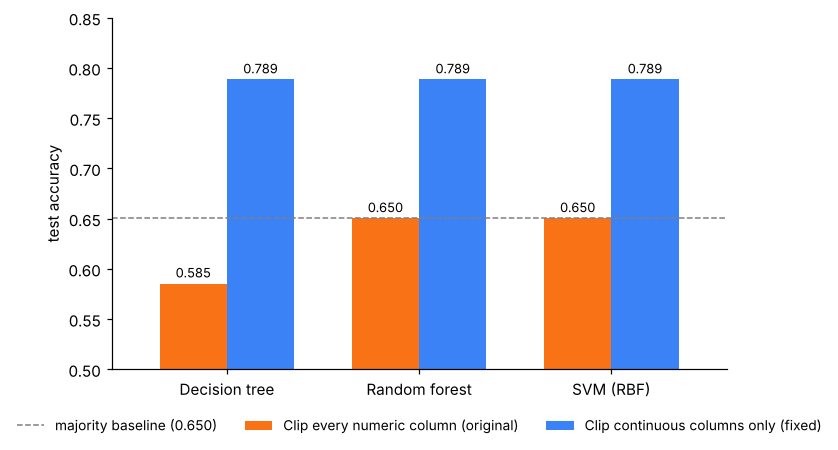

In [7]:
pivot = results.pivot(index="model", columns="setting", values="test accuracy")[list(settings)]
ax = pivot.plot.bar(figsize=(7.5, 4.2), color=["#f97316", "#3b82f6"], width=0.7, rot=0)
ax.axhline(baseline, ls="--", color="gray", lw=1, label=f"majority baseline ({baseline:.3f})")
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("test accuracy")
ax.set_xlabel("")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8.5, padding=2)
plt.tight_layout()
plt.savefig("assets/test_accuracy_comparison.png", bbox_inches="tight")
plt.show()

With the column intact, all three models land on the same test accuracy, because a shallow tree on `Credit_History` already captures most of the signal. With it destroyed, none of them beats the baseline: the tuning, model choice and extra features in the original assignment were all working on data that no longer contained the answer.

## 4. A second trap: choosing the threshold on the test set

The original extra-credit model picked the decision threshold that maximised accuracy **on the test set** and reported the result as its test score. The threshold is a hyperparameter, so it should come from training data (here, out-of-fold predictions). On this model the gap is small, but the peeked number is optimistic by construction, and on a 123-row test set a single threshold choice can move accuracy by several points.

In [8]:
best_rf = fitted[("Clip continuous columns only (fixed)", "Random forest")]
oof = cross_val_predict(best_rf, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
test_proba = best_rf.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
acc_oof = [accuracy_score(y_tr, oof >= t) for t in grid]
acc_test = [accuracy_score(y_te, test_proba >= t) for t in grid]
t_honest = grid[int(np.argmax(acc_oof))]
t_peek = grid[int(np.argmax(acc_test))]

print(f"threshold chosen on out-of-fold train predictions: {t_honest:.2f} -> test accuracy {accuracy_score(y_te, test_proba >= t_honest):.3f}")
print(f"threshold chosen on the test set itself:           {t_peek:.2f} -> test accuracy {max(acc_test):.3f}  (optimistic)")

threshold chosen on out-of-fold train predictions: 0.47 -> test accuracy 0.789
threshold chosen on the test set itself:           0.39 -> test accuracy 0.797  (optimistic)


## Takeaways

- A generic outlier rule applied to every numeric column can silently erase a binary or near-constant feature. Checking `nunique()` before and after each preprocessing step would have caught it immediately.
- Always report the majority-class baseline next to accuracy. The original models looked "low but plausible" until compared with it.
- Anything chosen by looking at the test set (thresholds included) makes the test score optimistic.